In [41]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import cartopy.crs as ccrs
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER 
import matplotlib.ticker as mticker 
from mpl_toolkits.axes_grid1.inset_locator import mark_inset 
import cartopy.feature as cfeature 
from matplotlib.patches import Rectangle
from matplotlib.colors import ListedColormap,BoundaryNorm
import netCDF4 as nc

import matplotlib.path as mpath
import matplotlib.patches as patches

In [42]:
Das=nc.Dataset('..\cmems_obs-sl_glo_phy-ssh_my_allsat-l4-duacs-0.25deg_P1M-m_1697447293140.nc')
SLA=np.array(Das.variables['sla'][:])
SLA[SLA<-1000]=np.nan
SLAM=np.mean(SLA,axis=0)
lon=np.array(Das.variables['longitude'][:])
lat=np.array(Das.variables['latitude'][:])
LON,LAT=np.meshgrid(lon,lat)

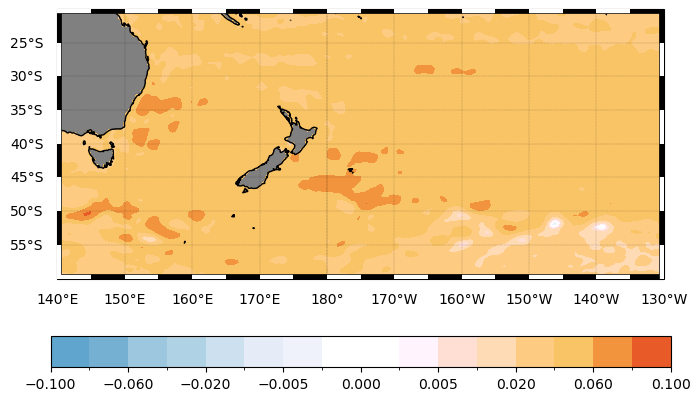

In [45]:
fig,ax=plt.subplots(1,1,figsize=(10,5),subplot_kw={'projection':ccrs.PlateCarree(central_longitude=180)})

## SEB ##
ax.coastlines()
ax.add_feature(cfeature.LAND,color='grey')
ax.add_feature(cfeature.COASTLINE,lw=0.25)
colors = ['#5fa5cd', '#75b0d3', '#89bbd9', '#9dc7df', '#b0d2e5', '#bfd9ea', '#cde0ef', '#dae7f4', '#e5ecf7', '#eff2fa', '#f8f8fc', '#ffffff','#ffffff','#ffffff', '#fff4fd', '#ffe8ee', '#ffded3', '#ffdbb5', '#ffd39b', '#fdcb81', '#f9c466', '#f6ac50', '#f2933d', '#ee7830', '#e95a29']
cmap = ListedColormap(colors)
levels=[-0.1,  -0.08,-0.06,-0.04,-0.02,-0.01,-0.005,-0.002,0.,0.002,0.005,0.01,0.02,0.04,0.06,0.08,0.1]
norm = BoundaryNorm(levels, cmap.N)
## SEB ##

c=plt.contourf(LON,LAT,SLAM,cmap=cmap,norm=norm,levels=levels,transform=ccrs.PlateCarree(0))
cb=plt.colorbar(c,orientation='horizontal',shrink=0.8,extend='max')

## HAN 黑白框 ##
[ax_hdl] = ax.plot(
    [
        140,145,150,155,160,165,170,175,180,185,190,195,200,205,210,215,220,225,
        230,230,230,230,230,230,230,230,230,
        225,220,215,210,205,200,195,190,185,180,175,170,165,160,155,150,145,
        140,140,140,140,140,140,140,140,140,
        140
    ],
    [
        -60,-60,-60,-60,-60,-60,-60,-60,-60,-60,-60,-60,-60,-60,-60,-60,-60,-60,
        -60,-55,-50,-45,-40,-35,-30,-25,-20,
        -20,-20,-20,-20,-20,-20,-20,-20,-20,-20,-20,-20,-20,-20,-20,-20,-20,
        -20,-25,-30,-35,-40,-45,-50,-55,-60,
        -60
    ],
    color='black', linewidth=0.5, marker='none',transform=ccrs.PlateCarree(0))
path_in_data_coords, _ = ax_hdl._get_transformed_path().get_transformed_path_and_affine()
polygon1s = mpath.Path( path_in_data_coords.vertices)
vcode =vcode = [1,2,1,2,1,2,1,2,1,2,1,2,1,2,1,2,1,2,1,2,1,2,1,2,1,2,1,1,2,1,2,1,2,1,2,1,2,1,2,1,2,1,2,1,2,1,2,1,2,1,2,1,2,1]
polygon1v = mpath.Path( path_in_data_coords.vertices, vcode)
patch1s = patches.PathPatch(polygon1s, facecolor='none', ec="black", lw=7, zorder=100)
patch1v = patches.PathPatch(polygon1v, facecolor='none', ec="white", lw=6, zorder=101)
ax.add_patch(patch1s)
ax.add_patch(patch1v)
ax.set_xlim(-40,50)
ax.set_ylim(-60,-20)
## HAN 黑白框 ##

## HAN 标签距离 ##
gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True, linewidth=0.2, color='k', alpha=0.5, linestyle='--')
gl.top_labels = False
gl.xlocator = mticker.FixedLocator(np.concatenate([np.arange(140,181,10),np.arange(-180,-129,10)]))
gl.xpadding=10
gl.ypadding=10
## HAN 标签距离 ##
plt.savefig('Fig1.png',dpi=300,bbox_inches='tight')
